# Análise exploratória dos dados do case Vício

Este notebook descreve as 359 questões de `anexos/questoes.jsonl` e os 377 temas de `anexos/temas.csv` antes de qualquer classificação. Nada aqui chama API de modelo: só Pandas, as funções de carga de `classificador.dados` e `classificador.arvore` e as heurísticas testadas em `analise/heuristicas.py`. O resumo para leitura fica em `analise/achados.md`.

**Como reconstruir.** Da raiz do repositório:

```bash
uv run python analise/construir_notebook.py && uv run jupyter nbconvert --to notebook --execute --inplace analise/analise_exploratoria.ipynb
```

O primeiro comando grava as células a partir de `analise/construir_notebook.py`, que é a fonte do notebook (edite lá, não aqui); o segundo executa o notebook no lugar e grava as saídas, com os gráficos embutidos.

**Kernel.** A execução usa o kernel `python3` que o `ipykernel` do grupo dev instala dentro do `.venv`; sob `uv run` ele roda com o Python do projeto e não precisa de registro. Se o `nbconvert` não achar o kernel, registre um com `uv run python -m ipykernel install --user --name case-vicio` e acrescente `--ExecutePreprocessor.kernel_name=case-vicio` ao segundo comando. A execução leva poucos segundos; em máquina lenta, acrescente `--ExecutePreprocessor.timeout=600`.

**Seções.** 1. Visão geral das questões · 2. Árvore de temas · 3. Evidência das lixeiras · 4. Casos destacados · 5. Heurística de OCR · 6. Gráficos · 7. Implicações para o pipeline.

In [1]:
import sys
from pathlib import Path


def achar_raiz(inicio: Path) -> Path:
    # Sobe a partir do diretório de execução até achar o pyproject.toml do repositório,
    # para o notebook rodar tanto de analise/ quanto da raiz.
    for pasta in [inicio, *inicio.parents]:
        if (pasta / "pyproject.toml").exists():
            return pasta
    raise FileNotFoundError("pyproject.toml não encontrado acima do diretório de execução")


RAIZ = achar_raiz(Path.cwd().resolve())
if str(RAIZ) not in sys.path:
    sys.path.insert(0, str(RAIZ))

import re
import textwrap
import unicodedata
from collections import Counter

import numpy as np
import pandas as pd
from IPython.display import Markdown, display

from analise import heuristicas
from classificador.arvore import EXCECOES_CANONICAS, ArvoreTemas
from classificador.config import SEMENTE
from classificador.dados import carregar_questoes, carregar_temas, limpar_html

pd.set_option("display.max_colwidth", 120)
pd.set_option("display.max_rows", 80)
pd.set_option("display.width", 200)

questoes = carregar_questoes()
temas = carregar_temas()
arvore = ArvoreTemas(temas)
por_id = questoes.set_index("id")
textos_dos_temas = list(temas["caminho"]) + list(temas["descricao"])


def imprimir_texto(id_questao: str, limite: int | None = None) -> None:
    # Texto de classificação (enunciado, comando e alternativas, já limpos), quebrado em linhas de 110.
    texto = por_id.loc[id_questao, "texto"]
    if limite is not None and len(texto) > limite:
        texto = texto[:limite].rstrip() + " [...]"
    for linha in texto.splitlines():
        print(textwrap.fill(linha, width=110))


print(f"{len(questoes)} questões e {len(temas)} temas carregados de anexos/")

359 questões e 377 temas carregados de anexos/


## 1. Visão geral das questões

Contagens por disciplina e assunto de origem, formato das alternativas, tamanho do enunciado, presença de comando e tags HTML. `disciplina_origem` e `assunto_origem` vêm da fonte e não são confiáveis: a mesma disciplina aparece com nomes diferentes ("Penal" e "Direito Penal", "Processo Penal" e "Direito Processual Penal"), e a seção 3 mostra que vários assuntos são lixeiras.

In [2]:
disciplina = questoes["disciplina_origem"].str.strip()
por_disciplina = (
    disciplina.where(disciplina != "", "(vazio)")
    .value_counts()
    .rename_axis("disciplina_origem")
    .to_frame("questoes")
)
por_disciplina["no_escopo"] = por_disciplina.index.isin(heuristicas.DISCIPLINAS_NO_ESCOPO)
no_escopo = por_disciplina.loc[por_disciplina["no_escopo"], "questoes"].sum()
print(f"{len(por_disciplina)} rótulos de disciplina; {no_escopo} questões no escopo e {len(questoes) - no_escopo} fora dele")
por_disciplina

12 rótulos de disciplina; 351 questões no escopo e 8 fora dele


,questoes,no_escopo
disciplina_origem,,
Processo Penal,131,True
Direito Penal,129,True
Direito Penal - Legislação Especial,32,True
Criminologia,31,True
Penal,27,True
Direito Constitucional,2,False
Direito Civil - Legislação Especial,2,False
Disciplina Unificada,1,False
(vazio),1,False


In [3]:
assunto = questoes["assunto_origem"].str.strip()
print(f"{assunto[assunto != ''].nunique()} assuntos de origem distintos; {(assunto == '').sum()} questões sem assunto")
assunto.where(assunto != "", "(vazio)").value_counts().head(15).rename_axis("assunto_origem").to_frame("questoes")

94 assuntos de origem distintos; 18 questões sem assunto


,questoes
assunto_origem,
Concurso de Crimes,43
Ação Penal,20
Ação Penal (Parte 01),19
Inquérito Policial,19
Teoria da Pena (Parte 02),18
(vazio),18
Ação Penal (Parte 02),17
Comunicação dos atos processuais,13
Teorias Legitimidoras da Pena,10


In [4]:
def formato(alternativas: dict) -> str:
    letras = "".join(alternativas)
    if letras == "CE":
        return "Certo/Errado (C, E)"
    return f"{len(alternativas)} alternativas ({letras[0]} a {letras[-1]})"


questoes["formato"] = questoes["alternativas"].map(formato)
questoes["n_alternativas"] = questoes["alternativas"].map(len)
(
    questoes.groupby("formato")
    .agg(alternativas=("n_alternativas", "first"), questoes=("id", "size"))
    .sort_values("alternativas")
)

,alternativas,questoes
formato,,
"Certo/Errado (C, E)",2,58
4 alternativas (A a D),4,46
5 alternativas (A a E),5,255


In [5]:
questoes["enunciado_limpo"] = questoes["enunciado_html"].map(limpar_html)
tamanho = questoes["enunciado_limpo"].str.len()
resumo_tamanho = pd.Series({
    "mínimo": tamanho.min(),
    "quartil 1": tamanho.quantile(0.25),
    "mediana": tamanho.median(),
    "quartil 3": tamanho.quantile(0.75),
    "máximo": tamanho.max(),
}).round().astype(int)
print("Caracteres do enunciado limpo (sem comando e sem alternativas); o histograma está na seção 6.")
print(resumo_tamanho.to_string())
faixas = pd.cut(
    tamanho,
    bins=[0, 60, 200, 500, 1000, 3000],
    labels=["até 60", "61 a 200", "201 a 500", "501 a 1000", "mais de 1000"],
)
faixas.value_counts(sort=False).rename_axis("caracteres").to_frame("questoes")

Caracteres do enunciado limpo (sem comando e sem alternativas); o histograma está na seção 6.
mínimo          9
quartil 1      89
mediana       201
quartil 3     516
máximo       2452


,questoes
caracteres,
até 60,51
61 a 200,128
201 a 500,88
501 a 1000,62
mais de 1000,30


In [6]:
sem_comando = questoes["comando"].str.strip() == ""
print(f"{sem_comando.sum()} questões sem comando ({sem_comando.mean():.0%})")
pd.crosstab(questoes["formato"], sem_comando.map({True: "sem comando", False: "com comando"}))

94 questões sem comando (26%)


comando,com comando,sem comando
formato,,
4 alternativas (A a D),29,17
5 alternativas (A a E),186,69
"Certo/Errado (C, E)",50,8


In [7]:
_TAG = re.compile(r"<\s*([a-zA-Z][\w:.-]*)")
TAGS_DE_FORMATACAO = {"br", "i", "b", "u", "sup", "span", "p", "em"}


def tags_de(html: str) -> set[str]:
    # Tags de abertura; as do Word com prefixo (w:View, o:p, m:mathPr) viram "w:*", "o:*", "m:*".
    nomes = {nome.lower() for nome in _TAG.findall(html or "")}
    return {nome.split(":")[0] + ":*" if ":" in nome else nome for nome in nomes}


campos = {
    "enunciado": questoes["enunciado_html"],
    "comando": questoes["comando"],
    "alternativas": questoes["alternativas"].map(lambda alternativas: " ".join(alternativas.values())),
}
tags = pd.DataFrame({
    campo: Counter(tag for html in serie for tag in tags_de(html)) for campo, serie in campos.items()
}).fillna(0).astype(int)
tags = tags.loc[tags.sum(axis=1).sort_values(ascending=False).index].rename_axis("tag")

todas_as_tags = [set().union(*(tags_de(serie.iloc[i]) for serie in campos.values())) for i in range(len(questoes))]
com_tag_estranha = [i for i, conjunto in zip(questoes["id"], todas_as_tags) if conjunto - TAGS_DE_FORMATACAO]
com_imagem = [i for i, conjunto in zip(questoes["id"], todas_as_tags) if "img" in conjunto]
alternativa_word = por_id.loc["Q0099", "alternativas"]["B"]
print("Número de questões em que cada tag aparece, por campo.")
print(f"Questões com tag além da formatação simples: {com_tag_estranha}")
print(f"Questões com imagem: {len(com_imagem)}")
print(f"Q0099, alternativa B: {len(alternativa_word)} caracteres de HTML do Word; depois de limpar_html, {len(limpar_html(alternativa_word))}")
tags

Número de questões em que cada tag aparece, por campo.
Questões com tag além da formatação simples: ['Q0099']
Questões com imagem: 0
Q0099, alternativa B: 35771 caracteres de HTML do Word; depois de limpar_html, 166


,enunciado,comando,alternativas
tag,,,
br,125,8,30
i,31,0,8
b,30,0,1
span,3,2,11
sup,6,0,3
u,7,0,0
p,2,0,4
o:*,0,0,1
style,0,0,1


## 2. Árvore de temas

Os 377 temas têm quatro disciplinas como raiz (nível 0), temas no nível 1 e subtemas no nível 2. Aqui ficam a estrutura por disciplina e nível, os defeitos que `defeitos_da_arvore` encontra, os 20 duplicados com o tema canônico para onde o pipeline os converte (`ArvoreTemas.duplicados()`) e os temas que a fonte diz ter zero questões.

In [8]:
estrutura = pd.crosstab(temas["disciplina"], temas["nivel"], margins=True, margins_name="total")
estrutura.columns = [coluna if coluna == "total" else f"nível {coluna}" for coluna in estrutura.columns]
print(temas["status"].value_counts().to_string())
estrutura

status
active      375
inactive      2


,nível 0,nível 1,nível 2,total
disciplina,,,,
Criminologia,1,11,14,26
Direito Penal - Legislação Especial,1,26,0,27
Penal,1,46,139,186
Processo Penal,1,28,109,138
total,4,111,262,377


In [9]:
defeitos = heuristicas.defeitos_da_arvore(temas)
display(defeitos["defeito"].value_counts().rename_axis("defeito").to_frame("temas"))
defeitos

,temas
defeito,
duplicado_sem_descricao,20
zero_questoes,7
titulo_com_erro,7
inativo,2
descricao_com_caracteres_estranhos,1


,tema_id,titulo,defeito
0,6716,Abuso de Autoridade,duplicado_sem_descricao
1,6717,Crimes contra o meio ambiente,duplicado_sem_descricao
2,6718,Dos Crimes Contra a Administração Pública (Parte 1),duplicado_sem_descricao
3,6719,Dos Crimes contra a Administração Pública (Parte 2),duplicado_sem_descricao
4,6720,Dos Crimes Contra o Patrimônio (Parte 1),duplicado_sem_descricao
5,6721,Dos Crimes contra o Patrimônio (Parte 2),duplicado_sem_descricao
6,6722,Estatuto do Idoso - Crimes,duplicado_sem_descricao
7,6723,Lavagem de Dinheiro,duplicado_sem_descricao
8,6724,Lei Maria da Penha,duplicado_sem_descricao
9,6725,Organizações Criminosas,duplicado_sem_descricao


In [10]:
duplicados = pd.DataFrame([
    {
        "duplicado": duplicado,
        "caminho_do_duplicado": arvore.caminho(duplicado),
        "canonico": canonico,
        "caminho_do_canonico": arvore.caminho(canonico),
        "como_casou": "exceção manual" if duplicado in EXCECOES_CANONICAS else "título normalizado",
    }
    for duplicado, canonico in sorted(arvore.duplicados().items())
])
print(
    f"{len(duplicados)} duplicados: {duplicados['como_casou'].eq('título normalizado').sum()} por título normalizado, "
    f"{duplicados['como_casou'].eq('exceção manual').sum()} pela tabela de exceções"
)
duplicados

20 duplicados: 17 por título normalizado, 3 pela tabela de exceções


,duplicado,caminho_do_duplicado,canonico,caminho_do_canonico,como_casou
0,6716,Penal > Abuso de Autoridade,4684,Direito Penal - Legislação Especial > Abuso de Autoridade,título normalizado
1,6717,Penal > Crimes contra o meio ambiente,4688,Direito Penal - Legislação Especial > Crimes contra o meio ambiente,título normalizado
2,6718,Penal > Dos Crimes Contra a Administração Pública (Parte 1),5087,Penal > Dos Crimes Contra a Administração Pública,título normalizado
3,6719,Penal > Dos Crimes contra a Administração Pública (Parte 2),5087,Penal > Dos Crimes Contra a Administração Pública,título normalizado
4,6720,Penal > Dos Crimes Contra o Patrimônio (Parte 1),5157,Penal > Dos Crimes Contra o Patrimônio,título normalizado
5,6721,Penal > Dos Crimes contra o Patrimônio (Parte 2),5157,Penal > Dos Crimes Contra o Patrimônio,título normalizado
6,6722,Penal > Estatuto do Idoso - Crimes,4696,Direito Penal - Legislação Especial > Estaturo de Idoso - Crimes,exceção manual
7,6723,Penal > Lavagem de Dinheiro,4702,Direito Penal - Legislação Especial > Lavagem de Dinheiro,título normalizado
8,6724,Penal > Lei Maria da Penha,4704,Direito Penal - Legislação Especial > Lei Maria da Penha,título normalizado
9,6725,Penal > Organizações Criminosas,4705,Direito Penal - Legislação Especial > Organizações Criminosas,título normalizado


In [11]:
zero_questoes = defeitos[defeitos["defeito"] == "zero_questoes"].merge(temas[["tema_id", "caminho"]], on="tema_id")
zero_questoes["candidato_no_pipeline"] = zero_questoes["tema_id"].map(arvore.publicavel)
inativos = defeitos[defeitos["defeito"] == "inativo"]["tema_id"].tolist()
print(f"Inativos, fora dos candidatos: {inativos}; publicáveis? {[arvore.publicavel(t) for t in inativos]}")
zero_questoes[["tema_id", "caminho", "candidato_no_pipeline"]]

Inativos, fora dos candidatos: [5078, 5234]; publicáveis? [False, False]


,tema_id,caminho,candidato_no_pipeline
0,5090,Penal > Dos Crimes Contra a Administração Pública > Emprego Irregular de Verbas ou Rendas Públicas,True
1,5139,Penal > Dos Crimes Contra a Periclitação da Vida e da Saúde > Perigo de Contágio Venéreo e de Moléstia Grave,True
2,5163,Penal > Dos Crimes Contra o Patrimônio > Usurpação,True
3,5190,Penal > Prescrição > Outras Prescrições,True
4,5522,Processo Penal > Prisões em Espécie > Medidas Cautelares Diversas da Prisão,True
5,5549,Processo Penal > Provas em Espécies > Declaração do Ofendido,True
6,5558,Processo Penal > Provas em Espécies > Ação Controlada,True


## 3. Evidência das lixeiras

O enunciado do case avisa que alguns assuntos de origem são lixeiras: rótulos largos onde caiu de tudo. Para os 6 assuntos mais frequentes (sem contar o vazio), cada tabela mostra 8 questões sorteadas com a semente do projeto, com o início do enunciado e o da alternativa A (em Certo/Errado, a primeira alternativa, que é sempre "Certo"). A coluna da alternativa ajuda quando o enunciado é genérico.

In [12]:
contagem_assuntos = assunto[assunto != ""].value_counts()
mais_frequentes = list(contagem_assuntos.head(6).index)


def amostra_do_assunto(nome: str, n: int = 8) -> pd.DataFrame:
    do_assunto = questoes[assunto == nome]
    amostra = do_assunto.sample(min(n, len(do_assunto)), random_state=SEMENTE).sort_values("id")
    primeira = amostra["alternativas"].map(lambda alternativas: alternativas.get("A") or next(iter(alternativas.values())))
    return pd.DataFrame({
        "id": amostra["id"],
        "inicio_do_enunciado": amostra["enunciado_limpo"].str[:110],
        "inicio_da_alternativa_a": primeira.map(limpar_html).str[:70],
    }).reset_index(drop=True)


for nome in mais_frequentes:
    display(Markdown(f"**{nome}**: {contagem_assuntos[nome]} questões"))
    display(amostra_do_assunto(nome))

**Concurso de Crimes**: 43 questões

,id,inicio_do_enunciado,inicio_da_alternativa_a
0,Q0039,Suponha que todos os revendedores de gás liquefeito de petróleo (GLP) ajustem artificialmente preço final de v,o ajuste é comum e em nada influencia na concorrência entre as empresa
1,Q0085,"No crime de concussão, a circunstância de ser um dos agentes funcionário público","não é elementar, não se comunicando, portanto, ao concorrente particul"
2,Q0181,"Identifique o que constitui crime contra a ordem tributária e assinale a alternativa correta . I Adquirir, dis",Apenas II e III estão corretas.
3,Q0182,Analise os itens e assinale a quantidade de itens errados . I - A instigação da gestante para permitir que ter,Um.
4,Q0307,"Determinado policial militar efetuou a prisão em flagrante de Luciano e o conduziu à delegacia de polícia. Lá,",Certo
5,Q0316,"Considere a seguinte situação: A, que acabara de ter um filho, que morre logo a seguir, sob a influência do es",Pela aplicação da teoria da equivalência.
6,Q0317,"O direito de representação deve ser exercido no prazo de seis meses contados a partir da data do fato, uma vez",Certo
7,Q0337,"A Lei nº 13.869/2019 dispõe sobre os crimes de abuso de autoridade. Sobre o assunto, analise as afirmativas ab",V - V - V


**Ação Penal**: 20 questões

,id,inicio_do_enunciado,inicio_da_alternativa_a
0,Q0007,"Gilson foi denunciado por tráfico de drogas e, no curso da audiência de instrução de julgamento, sua irmã Regi",todos os crimes são de ação penal pública condicionada à representação
1,Q0025,"A conduta do particular de solicitar vantagem de contribuinte autuado pela fiscalização, a pretexto ilusório d",Certo
2,Q0113,"José, Auditor Fiscal da Receita do Estado Beta, aceitou propina para deixar de constituir, mediante lançamento","Não deve ser aplicado, na esfera disciplinar, o prazo prescricional pr"
3,Q0152,"Nos crimes de ação privada, se comparecer mais de uma pessoa com direito de queixa, terá preferência, numa ord",o parente mais próximo na ordem de vocação sucessória.
4,Q0222,Assinale a alternativa correta.,"O denominado direito penal do inimigo, que tem como expoente Günther J"
5,Q0290,"No que diz respeito ao preceituado na Lei nº 9.099/1995, a qual disciplina os Juizados especiais criminais, as","A ação penal relativa ao crime de lesão corporal dolosa, em todas as s"
6,Q0305,A ação penal pública é de iniciativa exclusiva do Ministério Público e tem por objetivo dar concretude ao jus,"O prazo para oferecimento da denúncia é de 5 (cinco) dias, caso o acus"
7,Q0325,"Considerando as afirmativas abaixo, é CORRETO afirmar que:","A extinção da punibilidade, nos casos de transação penal em crimes amb"


**Ação Penal (Parte 01)**: 19 questões

...

,id,inicio_do_enunciado,inicio_da_alternativa_a
0,Q0015,"Com relação ao inquérito policial, segundo o Código de Processo Penal.",A polícia judiciária será exercida pelas autoridades policiais em todo
1,Q0032,"Quando, no curso da investigação, houver motivo para duvidar da integridade mental do investigado, a autoridad","concluir a investigação e, no relatório, informar tal circunstância, q"
2,Q0063,"No contexto da violência doméstica e familiar contra a mulher, avalie se as afirmativas a seguir são verdadeir",F – V – V – F.
3,Q0104,"No que se refere à legislação processual e à jurisprudência pátrias, julgue o item subsequente. O fato de o in",Certo
4,Q0149,"Relativamente ao inquérito policial e às diligências neste levadas a efeito, é correto afirmar que:","na busca domiciliar fundada em ordem judicial, quando encontrada a arm"
5,Q0193,"Sobre o tema da colaboração premiada, assinale a alternativa incorreta :","O acordo de colaboração premiada poderá ser precedido de instrução, qu"
6,Q0209,"Acerca das provas, das sentenças e dos princípios do direito processual penal, julgue o item a seguir. Em razã",Certo
7,Q0320,"O Direito Processual Penal, doutrinariamente, elenca as espécies de testemunhas. Dentre elas há a chamada test",é a testemunha que depõe sobre algum fato que ouviu dizer.


**Teoria da Pena (Parte 02)**: 18 questões

,id,inicio_do_enunciado,inicio_da_alternativa_a
0,Q0008,A progressão de regime do cumprimento da pena de condenado por crime contra a administração pública condiciona,Certo
1,Q0043,"Sobre a fixação da pena, tem-se o seguinte:",a existência de circunstância atenuante pode conduzir à redução da pen
2,Q0052,"Uma pessoa presa em regime fechado, definitivamente condenada, prestou 300 dias de trabalho prisional intra mu","II, III e IV."
3,Q0074,Considere a seguinte situação hipotética. Antônio foi condenado pela prática do delito X pelo juízo da 5.ª var,Certo
4,Q0125,"A Lei Antitóxicos (Lei n o 11.343/06) estabelece diminuição de pena no caso de agente primário, de bons antece","para o Tribunal ou o juízo da Vara das Execuções Criminais, indistinta"
5,Q0166,"O Defensor Público, na data de 15 de junho de 2010, ao atender os apenados da Casa do Albergado de um Municípi",o livramento condicional.
6,Q0250,"Sobre a determinação do regime inicial de cumprimento de pena, é correto afirmar que","em virtude do princípio da individualização da pena, a primeira fase d"
7,Q0313,"A condenação tem como efeito genérico tornar certa a obrigação de reparar o dano. Esse efeito é automático, nã",Certo


**Ação Penal (Parte 02)**: 17 questões

,id,inicio_do_enunciado,inicio_da_alternativa_a
0,Q0003,"Francisco foi processado pelo Ministério Público pelo delito de furto. Contudo, após a resposta preliminar, fo","recurso em sentido estrito a ser interposto pelo Ministério Público e,"
1,Q0020,Assinale com V (verdadeiro) ou com F (falso) as seguintes afirmações sobre posições jurisprudenciais do Superi,V – F – V – V – F.
2,Q0151,"No que diz respeito às prisões e medidas cautelares no processo penal, assinale a alternativa CORRETA:",O juiz poderá substituir a prisão preventiva pela domiciliar quando o
3,Q0200,"No que diz respeito às organizações criminosas, assinale a opção correta.",O líder de organização criminosa condenado pelo crime de integrar tal
4,Q0228,"Se o defensor de um condenado preso entender que ele faz jus ao livramento condicional, deverá:","Solicitar ao Tribunal, mediante a impetração de habeas corpus;"
5,Q0252,"João, maior de setenta anos de idade ao tempo do fato, foi condenado pelo crime de estelionato à pena privativ","caso o presidente da República conceda a João graça parcial, o benefíc"
6,Q0332,"Acolhendo a proposta do Ministério Público aceita pelo autor da infração, o Juiz aplicará a pena restritiva de","tendo aceito a proposta de transação penal, pela prática de lesão corp"
7,Q0353,"Se, no curso da ação penal, o magistrado notar que a prescrição está prestes a ocorrer, poderá:","Sentenciar, independentemente da apresentação dos memoriais defensivos"


**Leitura das amostras.** Os rótulos vão de lixeira a razoável. Em "Concurso de Crimes", o maior assunto, nenhuma das 8 trata de concurso material, formal ou crime continuado: há crimes contra a ordem econômica e a ordem tributária (Q0039, Q0181), concussão (Q0085), crimes contra a pessoa (Q0182), tortura praticada por policial (Q0307), erro sobre a pessoa no infanticídio (Q0316), prazo de representação (Q0317) e abuso de autoridade (Q0337). "Ação Penal (Parte 02)" é igual: recurso contra absolvição sumária (Q0003), prisão e cautelares (Q0151), organizações criminosas (Q0200), livramento condicional (Q0228), prescrição (Q0353). "Ação Penal (Parte 01)" é quase todo de provas e recursos (Q0012, Q0098, Q0146, Q0226). "Ação Penal" e "Inquérito Policial" acertam em parte da amostra (Q0152 e Q0305; Q0015 e Q0149). Só "Teoria da Pena (Parte 02)" é coerente: aplicação da pena e execução penal (Q0043, Q0052, Q0250). O assunto de origem não serve de rótulo para as questões.

### Comparação com a decisão do pipeline

*Preenchido após a execução.* Quando o pipeline tiver decidido as 359 questões, esta seção cruza cada assunto de origem com o tema decidido, para medir quanto de cada lixeira foi parar em temas de outros ramos. Nenhuma célula deste notebook depende desses arquivos.

## 4. Casos destacados

Questões e temas que pedem tratamento próprio, cada um com o texto limpo impresso: é exatamente o texto que os modelos e os embeddings recebem (enunciado, comando e alternativas, sem HTML).

### 4.1 Disciplina de origem fora do escopo

In [13]:
fora_do_escopo = heuristicas.questoes_fora_do_escopo(questoes)
display(fora_do_escopo)
for id_questao, rotulo in zip(fora_do_escopo["id"], fora_do_escopo["disciplina_origem"]):
    print(f"\n--- {id_questao} ({rotulo.strip() or 'sem disciplina'})")
    imprimir_texto(id_questao, limite=350)

,id,disciplina_origem,assunto_origem,inicio
0,Q0014,Disciplina Unificada,Medidas Socioeducativas,"Caso a decisão do magistrado em relação à internação de Pedro seja questionada em juízo, ela não pode ser sanada pel..."
1,Q0016,Direito Constitucional,,"À luz da atual jurisprudência dos Tribunais Superiores sobre o tema prisão , avalie as assertivas a seguir. I. Conso..."
2,Q0036,,,"Em uma Vara de Violência Doméstica e Familiar contra a Mulher, o Juiz de Direito recebeu os autos de inquérito polic..."
3,Q0137,Direito Civil - Legislação Especial,,"No que dispõe a legislação sobre a investigação criminal, conduzida pelo delegado de polícia é CORRETO afirmar que:\..."
4,Q0142,Direito Tributário,Impostos Estaduais,"Assinale a alternativa que corresponde a uma operação isenta do Imposto sobre a Transmissão ""Causa Mortis"" e Doação ..."
5,Q0218,Direito Constitucional,,"João da Silva vai à agência bancária obter o levantamento de conta de FGTS de terceiro, usando documento falso. Desc..."
6,Q0277,Direito Civil - Legislação Especial,,"NÃO configura crime contra idoso:\nAlternativas:\nA) Induzir pessoa idosa, mesmo que com discernimento, a outorgar p..."
7,Q0309,Direito Ambiental,Sistema de responsabilização por ilícitos ambientais,Segundo o Artigo 61 da Lei nº 9.605/98 a pena para quem disseminar doença ou praga ou espécies que possam causar dan...



--- Q0014 (Disciplina Unificada)
Caso a decisão do magistrado em relação à internação de Pedro seja questionada em juízo, ela não pode ser
sanada pela via do habeas corpus , pois tal instrumento processual não se aplica às situações que envolvam
decisões tomadas por vara da infância e da juventude em detrimento da liberdade de criança ou adolescente.
Comando: Assinale a alternativ [...]

--- Q0016 (Direito Constitucional)
À luz da atual jurisprudência dos Tribunais Superiores sobre o tema prisão , avalie as assertivas a seguir. I.
Consoante a jurisprudência do Superior Tribunal de Justiça, em razão da Lei nº 13.964/2019, não é mais
possível ao Juiz, de ofício, decretar ou converter a prisão em flagrante em prisão preventiva. II. De acordo
com o entendimento do Supre [...]

--- Q0036 (sem disciplina)
Em uma Vara de Violência Doméstica e Familiar contra a Mulher, o Juiz de Direito recebeu os autos de inquérito
policial concluído, no qual se apurou a prática de crime de lesão corporal le

Pelo texto, só a Q0142 (isenção de ITCD, direito tributário) está fora das quatro disciplinas. As outras sete são matéria penal ou processual penal com rótulo errado: habeas corpus contra internação decidida na vara da infância (Q0014), prisão de ofício e preventiva (Q0016), lesão corporal em violência doméstica (Q0036), indiciamento e investigação conduzida pelo delegado (Q0137), uso de documento falso para sacar FGTS de terceiro (Q0218), crimes contra idoso (Q0277) e crime ambiental da Lei 9.605/98 (Q0309). O rótulo de disciplina não serve para decidir `fora`.

### 4.2 Enunciados genéricos e enunciados repetidos

In [14]:
genericos = questoes.loc[questoes["enunciado_limpo"].map(heuristicas.eh_enunciado_generico), "id"].tolist()
print(f"{len(genericos)} enunciados genéricos: {', '.join(genericos)}")
grupos = heuristicas.grupos_de_enunciado_repetido(questoes)
print(f"\n{len(grupos)} grupos de enunciado repetido:")
for grupo in grupos:
    enunciado = limpar_html(por_id.loc[grupo[0], "enunciado_html"])
    print(f"  {len(grupo)} questões com {enunciado!r}: {', '.join(grupo)}")
for id_questao in ("Q0090", "Q0205"):
    print(f"\n--- {id_questao}")
    imprimir_texto(id_questao)

20 enunciados genéricos: Q0037, Q0068, Q0090, Q0140, Q0172, Q0177, Q0192, Q0205, Q0222, Q0239, Q0245, Q0268, Q0282, Q0299, Q0321, Q0331, Q0333, Q0339, Q0340, Q0354

3 grupos de enunciado repetido:
  6 questões com 'Assinale a alternativa CORRETA.': Q0090, Q0205, Q0222, Q0299, Q0333, Q0339
  3 questões com 'Assinale a alternativa incorreta.': Q0172, Q0331, Q0354
  2 questões com 'Assinale a alternativa correta:': Q0268, Q0321

--- Q0090
Assinale a alternativa CORRETA.
Alternativas:
A) Em havendo reunião de processos perante o juízo comum ou o tribunal do júri, decorrentes da aplicação das
regras de conexão e continência, não serão observados os institutos da transação penal e da composição dos
danos civis, em relação aos crimes de menor potencial ofensivo.
B) Em razão de a Lei n° 9.099/95 admitir a aplicação subsidiária das disposições do Código de Processo Penal,
o juiz determinará a suspensão do processo e do curso do prazo prescricional sempre que, nos crimes submetidos
ao procedimen

Q0090 e Q0205 têm o mesmo enunciado e nada em comum além dele: o tema está todo nas alternativas.

### 4.3 Q0078, corrupção de OCR

O vocabulário usado aqui é o mesmo de `marcar_corrupcao_ocr`: palavras que aparecem em pelo menos 2 textos, sem contar a própria questão. A tabela completa está na seção 5.

In [15]:
ocr = heuristicas.marcar_corrupcao_ocr(questoes, temas=temas)
ocr["posicao"] = range(1, len(ocr) + 1)
ocr_por_id = ocr.set_index("id")
q0078 = ocr_por_id.loc["Q0078"]


def tokens_fora_do_vocabulario(id_questao: str) -> list[str]:
    # Mesmo vocabulário de marcar_corrupcao_ocr: os outros textos e os temas, palavra em 2 ou mais textos.
    outros = [texto for i, texto in zip(questoes["id"], questoes["texto"]) if i != id_questao]
    vocabulario = heuristicas.montar_vocabulario(outros + textos_dos_temas)
    return [t for t in dict.fromkeys(heuristicas.tokens(por_id.loc[id_questao, "texto"])) if t not in vocabulario]


print(f"Q0078: proporção fora do vocabulário {q0078['proporcao']:.3f}, {q0078['posicao']}ª maior de {len(ocr)}")
fora_q0078 = tokens_fora_do_vocabulario("Q0078")
print(f"{len(fora_q0078)} palavras distintas fora do vocabulário:")
print(textwrap.fill(", ".join(fora_q0078), width=110))
print()
imprimir_texto("Q0078")

Q0078: proporção fora do vocabulário 0.341, 12ª maior de 359


64 palavras distintas fora do vocabulário:
oossstomnioconcunsos, come, marcelo, valido, calibre, mantem, pistola, serie, raspada, recebera, andre,
foragido, pol, faleceu, pouco, vendeu, imil, reis, hugo, saiu, escondida, embaixo, frente, pretendia, trajeto,
habilitacao, permissao, dirigi, itercepiado, barreira, assustado, acelerou, fugiu, apes, colidiu, poste,
iluminacao, dagrante, conduzido, revistado, lavrou, fizendo, constar, ama, deflagrado, adquirido, estiveram,
encontraram, presenciaram, daniel, manuseando, municiado, encontrara, gaveta, banheiro, elaine, verificaram,
isava, colar, projetil, pendurado, pescoco, dirigir, cautela

EM oossstomnioconcunsos come Marcelo possui registro válido de um revólver de calibre 32 e o mantém em sua
residência, e também possui uma pistola de calibre .380, com número de série raspada, que recebera de André,
seu amigo foragido da pol a, que faleceu pouco tempo depois. Marcelo vendeu, por imil reis, a pistola a Hugo,
que saiu da residência de Marc

O texto está corrompido ("oossstomnioconcunsos", "itercepiado", "dagrante", "fizendo", "isava"), mas segue legível: dá para entender o caso de posse, porte e venda de arma. Das 64 palavras distintas fora do vocabulário, porém, só 11 são lixo de OCR (oossstomnioconcunsos, come, pol, imil, dirigi, itercepiado, apes, dagrante, fizendo, ama, isava); as outras 53 são palavras comuns que o corpus pequeno não repete ("pistola", "raspada", "embaixo", "trajeto", nomes próprios). É isso que impede a heurística de separar esta questão das outras (seção 5).

### 4.4 Q0240, `\t` literal nas alternativas

As alternativas da Q0240 trazem a sequência `\t` escrita como texto (barra invertida e "t", não um caractere de tabulação), herdada do banco de origem. `limpar_html` troca os `\n` e `\t` literais por espaço.

In [16]:
for letra, bruto in por_id.loc["Q0240", "alternativas"].items():
    print(f"{letra}  bruto: {bruto:<22} limpo: {limpar_html(bruto)}")
print()
imprimir_texto("Q0240")

A  bruto: 15\tdias;<br>          limpo: 15 dias;
B  bruto: 10\tdias;<br>          limpo: 10 dias;
C  bruto: 12\tdias;<br>          limpo: 12 dias;
D  bruto: 14\tdias;\t<br>        limpo: 14 dias;
E  bruto: 07 dias                limpo: 07 dias

Pedro, que estava indiciado por crime de roubo, teve sua prisão decretada pelo juiz da comarca de Miracema-RJ
em 08 de agosto de 2011, uma segunda-feira, sendo preso provisoriamente no mesmo dia, enquanto ainda estava
sendo investigado. Terminado o inquérito, o delegado, no último dia do prazo determinado em lei, fez logo cedo
a remessa a juízo. O juiz, no mesmo dia em que recebeu os autos, tendo-se em conta que era um dia útil, deu
vista pessoal ao promotor. Considerando-se o prazo legal que o promotor tem para oferecer a denúncia e que
esse prazo venceria em um dia útil, o trâmite do inquérito, o prazo utilizado pelo delegado, o recebimento e a
vista do inquérito pelo promotor e a denúncia contra Pedro, somando-se todos esses atos e prazos, de

### 4.5 Q0007, o personagem Gilson

A Q0007 tem um personagem chamado Gilson, o mesmo nome do autor deste trabalho. É coincidência da fonte; a questão é tratada como qualquer outra.

In [17]:
imprimir_texto("Q0007")

Gilson foi denunciado por tráfico de drogas e, no curso da audiência de instrução de julgamento, sua irmã
Regina, que aceitou prestar depoimento, narrou, além dos fatos descritos na denúncia, que Gilson é um irmão
ciumento e a ameaçou de morte e a xingou de “puta”, quando ela arrumou um namorado. Regina contou também que
Gilson, reiteradamente, a perseguia na faculdade e no trabalho e que, em certas ocasiões, sequer pode sair de
casa. Terminada a audiência, o Promotor de Justiça requereu ao Juiz cópia da mídia com o depoimento de Regina,
o que foi deferido. Em seguida, ofereceu denúncia em face de Gilson, imputando a ele os crimes de ameaça (Art.
147 do Código Penal), injúria (Art. 140 do Código Penal) e perseguição (Art. 147-A do Código Penal).
Comando: O Defensor Público encarregado de elaborar a resposta à acusação, deverá observar que
Alternativas:
A) todos os crimes são de ação penal pública condicionada à representação.
B) todos os crimes são de ação penal pública incondicionada.

### 4.6 Temas com título errado

A coluna `canonico_de` mostra quais duplicados apontam para o tema. O caso que importa é o 4696: o duplicado 6722 tem o título certo ("Estatuto do Idoso - Crimes"), mas o canônico, que é o id publicado, carrega o erro "Estaturo". O id está certo; o título errado vai para o relatório.

In [18]:
CORRECAO_PROVAVEL = {
    "Estaturo": "Estatuto",
    "Comeptência": "Competência",
    "Crimonológicas": "Criminológicas",
    "Crimescontra": "Crimes contra",
    "Falso Testemunha": "Falso Testemunho",
    "Testemunhavel": "Testemunhável",
    "Caractéristas": "Características",
}
titulos_errados = defeitos[defeitos["defeito"] == "titulo_com_erro"].merge(temas[["tema_id", "caminho"]], on="tema_id")
titulos_errados["correcao_provavel"] = titulos_errados["titulo"].map(
    lambda titulo: "; ".join(f"{errado} → {certo}" for errado, certo in CORRECAO_PROVAVEL.items() if errado in titulo)
)
titulos_errados["canonico_de"] = titulos_errados["tema_id"].map(
    lambda tema_id: [duplicado for duplicado, canonico in arvore.duplicados().items() if canonico == tema_id]
)
titulos_errados[["tema_id", "caminho", "correcao_provavel", "canonico_de"]]

,tema_id,caminho,correcao_provavel,canonico_de
0,4373,Criminologia > Etapas Evolutivas e Escolas Criminológicas > Escolas Crimonológicas,Crimonológicas → Criminológicas,[]
1,4696,Direito Penal - Legislação Especial > Estaturo de Idoso - Crimes,Estaturo → Estatuto,[6722]
2,5081,Penal > Dos Crimes Contra a Administração Judicial > Falso Testemunha ou Falsa Perícia e Corrupção Ativa de Testemun...,Falso Testemunha → Falso Testemunho,[]
3,5136,"Penal > Dos Crimes contra a Organização do Trabalho, a Propriedade Imaterial e ao Sentimento Religioso > Dos Crimesc...",Crimescontra → Crimes contra,[]
4,5483,Processo Penal > Competência > Comeptência Territorial,Comeptência → Competência,[]
5,5499,"Processo Penal > Inquérito Policial > Conceito, Finalidade e Caractéristas do Inquérito Policial",Caractéristas → Características,[]
6,5567,Processo Penal > Recursos em Espécies > Carta Testemunhavel,Testemunhavel → Testemunhável,[]


### 4.7 Descrição com caracteres estranhos

In [19]:
for tema_id in defeitos.loc[defeitos["defeito"] == "descricao_com_caracteres_estranhos", "tema_id"]:
    descricao = arvore.descricao(tema_id)
    posicoes = [i for i, c in enumerate(descricao) if unicodedata.name(c, "").startswith("ARABIC")]
    print(f"{tema_id} {arvore.caminho(tema_id)}")
    print(f"trecho: ...{descricao[posicoes[0] - 60:posicoes[-1] + 30]}...")
    print("caracteres:", ", ".join(f"{c} U+{ord(c):04X}" for c in dict.fromkeys(descricao[i] for i in posicoes)))
    print()
    print(textwrap.fill(descricao, width=110))

5530 Processo Penal > Procedimento Ordinário
trecho: ...umária, a instrução criminal, o interrogatório como meio de الدفاع, a oitiva de testemunhas, o ...
caracteres: ا U+0627, ل U+0644, د U+062F, ف U+0641, ع U+0639

O procedimento ordinário no Processo Penal disciplina o rito comum de maior amplitude para o processamento da
ação penal, especialmente nos crimes cuja pena máxima seja superior a 4 anos, conforme os arts. 394 a 405 do
Código de Processo Penal, com a redação dada pela Lei 11.719/2008. Abrange a denúncia ou queixa, o recebimento
da inicial, a citação do acusado, a resposta à acusação, a possibilidade de absolvição sumária, a instrução
criminal, o interrogatório como meio de الدفاع, a oitiva de testemunhas, o reconhecimento, a acareação, a
juntada de documentos, as diligências complementares e, ao final, as alegações finais e a sentença. Também se
relaciona aos princípios do contraditório, ampla defesa, oralidade, concentração dos atos e duração razoável
do processo, sob a l

A descrição do tema 5530 (Procedimento Ordinário) diz "o interrogatório como meio de الدفاع": a palavra árabe para "a defesa" no meio do português. Essa descrição entra no documento do tema que vira embedding; o efeito esperado é pequeno, porque o resto da descrição é longo e correto, mas fica registrado.

## 5. Heurística de OCR

Para cada questão, o vocabulário é o conjunto de palavras (3 ou mais letras, minúsculas, sem acento) que aparecem em pelo menos 2 textos, contando as outras 358 questões e os caminhos e descrições dos temas, sem a própria questão. A proporção é a fração das palavras da questão que ficam fora desse vocabulário; `suspeita` é proporção acima do limiar de 0,25. Texto corrompido gera palavras que não existem e sobe a proporção, mas vocabulário raro legítimo também sobe. A tabela traz as 10 maiores, com as primeiras palavras fora do vocabulário de cada uma.

In [20]:
topo = ocr.head(10).merge(questoes[["id", "disciplina_origem"]], on="id")
topo["exemplos_fora_do_vocabulario"] = topo["id"].map(lambda i: ", ".join(tokens_fora_do_vocabulario(i)[:8]))
topo["proporcao"] = topo["proporcao"].round(3)
topo[["posicao", "id", "proporcao", "suspeita", "disciplina_origem", "exemplos_fora_do_vocabulario"]]

,posicao,id,proporcao,suspeita,disciplina_origem,exemplos_fora_do_vocabulario
0,1,Q0076,0.456,True,Criminologia,"definida, tradicionalmente, empirica, mecanismos, fundaram, cesare, raffaele, franz"
1,2,Q0142,0.434,True,Direito Tributário,"corresponde, isenta, imposto, transmissao, mortis, doacao, itcd, morada"
2,3,Q0002,0.390,True,Criminologia,"vera, regina, pereira, andrade, clientela, constituida, pobres, tendencia"
3,4,Q0115,0.390,True,Criminologia,"mercado, estressante, demitido, mundo, desabara, pegou, queria, chegar"
4,5,Q0154,0.380,True,Direito Penal,"praticas, discriminatorias, gravidez, salarial, gravida, teste, relativo, esterilizacao"
5,6,Q0302,0.375,True,Penal,"cesar, acougueiro, trabalhando, regulamente, freezer, acougue, fugindo, esconde"
6,7,Q0066,0.371,True,Criminologia,"aprofundando, ideias, metodologico, rejeita, vies, etiologico, buscar, individualizador"
7,8,Q0083,0.359,True,Direito Penal,"osvaldo, disparou, arnaldo, susto, desmaiou, piamente, colocou, cova"
8,9,Q0344,0.357,True,Direito Penal,"derivadas, lesivas, animais, entregues, jardins, zoologi, cos, fundacoes"
9,10,Q0329,0.351,True,Processo Penal,"revelou, esquema, envolvia, competicao, futebolistica, cavalcante, dono, tapauense"


In [21]:
q0001 = ocr_por_id.loc["Q0001"]
print(f"Q0078 (corrompida): {q0078['proporcao']:.3f}, {q0078['posicao']}ª de {len(ocr)}; {q0078['posicao'] - 1} questões ficam acima dela")
print(f"Q0001 (limpa): {q0001['proporcao']:.3f}, {q0001['posicao']}ª de {len(ocr)}")
print(f"mediana {ocr['proporcao'].median():.3f}; percentil 90 {ocr['proporcao'].quantile(0.9):.3f}; máximo {ocr['proporcao'].max():.3f}")
for limiar in (0.25, 0.30, 0.34):
    print(f"proporção acima de {limiar:.2f}: {(ocr['proporcao'] > limiar).sum()} questões")
print(f"marcadas como suspeitas (limiar 0,25): {ocr['suspeita'].sum()} de {len(ocr)}")
print(f"\nacima da Q0078: {', '.join(ocr.loc[ocr['posicao'] < q0078['posicao'], 'id'])}")
for id_questao in ocr.loc[(ocr["posicao"] > len(topo)) & (ocr["posicao"] < q0078["posicao"]), "id"]:
    exemplos = ", ".join(tokens_fora_do_vocabulario(id_questao)[:8])
    print(f"{id_questao}, {ocr_por_id.loc[id_questao, 'posicao']}ª, fora da tabela acima: {exemplos}")

Q0078 (corrompida): 0.341, 12ª de 359; 11 questões ficam acima dela
Q0001 (limpa): 0.083, 284ª de 359
mediana 0.141; percentil 90 0.266; máximo 0.456
proporção acima de 0.25: 48 questões
proporção acima de 0.30: 20 questões
proporção acima de 0.34: 12 questões
marcadas como suspeitas (limiar 0,25): 48 de 359

acima da Q0078: Q0076, Q0142, Q0002, Q0115, Q0154, Q0302, Q0066, Q0083, Q0344, Q0329, Q0253
Q0253, 11ª, fora da tabela acima: positiva, entende, deriva, biologicas, defendida, feuerbach, funda, carrara


**O limiar e o que ele não faz.** A heurística não isola a questão corrompida. A Q0078 tem proporção 0,341 e fica em 12º lugar entre 359; a Q0001, limpa, tem 0,083. O percentil 90 é 0,266, e o limiar 0,25 marca 48 questões, 13% do total. As 11 que ficam acima da Q0078 são questões limpas com vocabulário raro num corpus pequeno: nomes de autores na criminologia (Cesare, Raffaele e Franz na Q0076, Vera Regina Pereira de Andrade na Q0002, Feuerbach e Carrara na Q0253), narrativas cheias de nomes e palavras do dia a dia (Q0115, Q0302, Q0083, Q0329) e matéria de outras áreas (ITCD na Q0142, Lei 9.029/95 na Q0154, Lei 9.605/98 na Q0344). No máximo aparecem palavras partidas, como "zoologi cos" na Q0344, não texto ilegível. Como a Q0078 está em 12º, nenhum limiar a marca sem marcar junto pelo menos 11 questões limpas.

Por isso o resultado é uma **lista de triagem ordenada para leitura humana, não um detector**. O limiar 0,25 fica porque marca a Q0078 e deixa a Q0001 de fora, um pouco abaixo do percentil 90; ele não muda nenhuma decisão do pipeline: o texto não é corrigido, e a marca de suspeita só vai para o relatório. Uma melhoria barata, fora do escopo desta análise, seria olhar só as palavras fora do vocabulário que são longas ou têm sequências improváveis de letras, como "oossstomnioconcunsos".

## 6. Gráficos

Cinco gráficos em matplotlib, seguindo o skill `dataviz`: cores da paleta de referência (azul para a série principal, laranja para o segundo grupo, cinza para o que é só contexto, rampa azul do claro ao escuro para o nível da árvore), barras finas com a ponta arredondada e a base reta, grade em linha fina e nenhum eixo duplo. As combinações passaram no validador de paleta do skill (azul e laranja nos testes de daltonismo, visão normal e contraste; a rampa de nível no teste ordinal; o cinza de contexto se separa do azul sob daltonismo e passa no contraste, e só reprova no croma, como todo cinza). Cada figura tem fundo claro próprio e opaco, então fica legível tanto no tema claro quanto no escuro do Jupyter ou do VS Code. Os mesmos números estão nas tabelas das seções 1, 2 e 5.

In [22]:
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.patches import Patch, PathPatch
from matplotlib.path import Path as Traco
from matplotlib.ticker import FuncFormatter

# Paleta de referência do skill dataviz, modo claro (a figura leva o próprio fundo).
SUPERFICIE = "#fcfcfb"
TINTA = "#0b0b0b"
TINTA_SECUNDARIA = "#52514e"
GRADE = "#e1e0d9"
EIXO = "#c3c2b7"
SERIE_1 = "#2a78d6"        # azul, posição 1 da paleta categórica
SERIE_2 = "#eb6834"        # laranja, posição 2
CONTEXTO = "#898781"       # cinza da forma de ênfase
NIVEL_1 = "#86b6ef"        # rampa ordinal azul, passo 250
NIVEL_2 = "#1c5cab"        # passo 550
DPI = 100
PX = 72 / DPI              # 1 pixel em pontos
RAIO = 4                   # px da ponta arredondada
FOLGA = 2                  # px de superfície entre marcas que se tocam
ESPESSURA_MAXIMA = 24      # px

_CODIGOS = [Traco.MOVETO, Traco.LINETO, Traco.CURVE3, Traco.CURVE3, Traco.LINETO,
            Traco.CURVE3, Traco.CURVE3, Traco.LINETO, Traco.CLOSEPOLY]


def virgula(casas: int) -> FuncFormatter:
    return FuncFormatter(lambda valor, _: f"{valor:.{casas}f}".replace(".", ","))


def nova_figura(largura: float, altura: float, titulo: str, subtitulo: str):
    fig, ax = plt.subplots(figsize=(largura, altura), dpi=DPI)
    fig.patch.set_facecolor(SUPERFICIE)
    ax.set_facecolor(SUPERFICIE)
    for lado in ax.spines.values():
        lado.set_visible(False)
    ax.tick_params(colors=TINTA_SECUNDARIA, labelsize=9, length=0, pad=6)
    ax.set_title(titulo, loc="left", color=TINTA, fontsize=12, pad=24)
    ax.annotate(subtitulo, xy=(0, 1), xycoords="axes fraction", xytext=(0, 8), textcoords="offset points",
                color=TINTA_SECUNDARIA, fontsize=9, va="bottom")
    ax.set_axisbelow(True)
    return fig, ax


def barra(ax, inicio, fim, centro, espessura_px, cor, horizontal=True, arredondar=True,
          recuo_inicio=0.0, recuo_fim=0.0):
    # Desenha em pixels: ponta de dados arredondada, base reta; volta para coordenadas de dados.
    tela = ax.transData
    if horizontal:
        (x0, yc), (x1, _) = tela.transform([(inicio, centro), (fim, centro)])
        x0, x1 = x0 + recuo_inicio, x1 - recuo_fim
        if x1 - x0 <= 0:
            return
        r = min(RAIO, x1 - x0, espessura_px / 2) if arredondar else 0.0
        b, t = yc - espessura_px / 2, yc + espessura_px / 2
        vertices = [(x0, b), (x1 - r, b), (x1, b), (x1, b + r), (x1, t - r), (x1, t), (x1 - r, t), (x0, t), (x0, b)]
    else:
        (xc, y0), (_, y1) = tela.transform([(centro, inicio), (centro, fim)])
        y0, y1 = y0 + recuo_inicio, y1 - recuo_fim
        if y1 - y0 <= 0:
            return
        r = min(RAIO, y1 - y0, espessura_px / 2) if arredondar else 0.0
        e, d = xc - espessura_px / 2, xc + espessura_px / 2
        vertices = [(d, y0), (d, y1 - r), (d, y1), (d - r, y1), (e + r, y1), (e, y1), (e, y1 - r), (e, y0), (d, y0)]
    em_dados = tela.inverted().transform(vertices)
    ax.add_patch(PathPatch(Traco(em_dados, _CODIGOS), facecolor=cor, edgecolor="none", zorder=2))


def preparar_barras_h(fig, ax, rotulos, maximo, eixo_de_valor=False, formato=None):
    # Primeiro rótulo em cima; fixa limites e layout antes de desenhar em pixels.
    n = len(rotulos)
    posicoes = list(range(n - 1, -1, -1))
    ax.set_ylim(-0.6, n - 0.4)
    ax.set_xlim(0, maximo)
    ax.set_yticks(posicoes, list(rotulos))
    if eixo_de_valor:
        ax.grid(axis="x", color=GRADE, linewidth=PX)
        if formato is not None:
            ax.xaxis.set_major_formatter(formato)
    else:
        ax.set_xticks([])
    ax.axvline(0, color=EIXO, linewidth=PX, zorder=3)
    fig.tight_layout()
    unidade_px = abs(ax.transData.transform((0, 1))[1] - ax.transData.transform((0, 0))[1])
    return posicoes, min(ESPESSURA_MAXIMA, 0.62 * unidade_px)


def rotulo_na_ponta(ax, valor, y, texto):
    ax.annotate(texto, xy=(valor, y), xytext=(5, 0), textcoords="offset points",
                va="center", ha="left", fontsize=9, color=TINTA_SECUNDARIA)


def rotulo_no_segmento(ax, inicio, fim, y, texto, cor, minimo_px=26):
    # Só escreve dentro do segmento quando o texto cabe com folga; senão a legenda e a tabela bastam.
    (x0, _), (x1, _) = ax.transData.transform([(inicio, y), (fim, y)])
    if x1 - x0 >= minimo_px:
        ax.text((inicio + fim) / 2, y, texto, ha="center", va="center", fontsize=9, color=cor, zorder=4)


def legenda(ax, itens, **opcoes):
    alcas = [
        Line2D([], [], color=cor, linewidth=1.5) if tipo == "linha"
        else Patch(facecolor=cor, edgecolor="none")
        for tipo, cor, _ in itens
    ]
    ax.legend(alcas, [texto for _, _, texto in itens], frameon=False, fontsize=9,
              labelcolor=TINTA_SECUNDARIA, handlelength=1.2, handleheight=0.9, **opcoes)

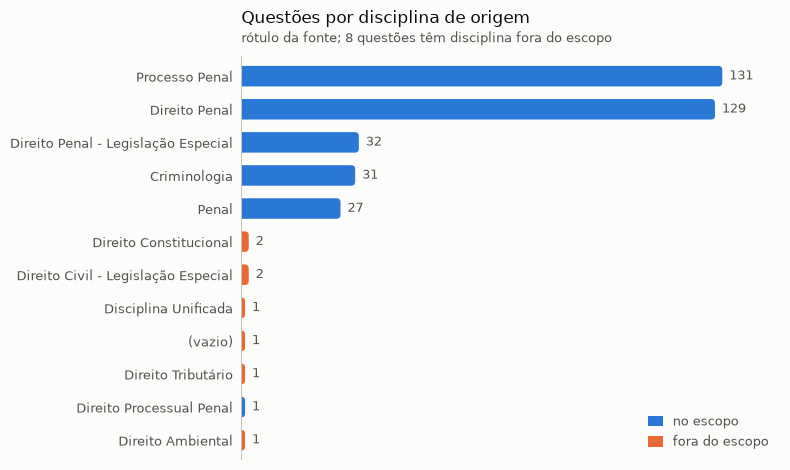

In [23]:
dados = por_disciplina.reset_index()
fora = dados.loc[~dados["no_escopo"], "questoes"].sum()
fig, ax = nova_figura(8, 4.8, "Questões por disciplina de origem",
                      f"rótulo da fonte; {fora} questões têm disciplina fora do escopo")
posicoes, espessura = preparar_barras_h(fig, ax, dados["disciplina_origem"], dados["questoes"].max() * 1.12)
for y, valor, dentro in zip(posicoes, dados["questoes"], dados["no_escopo"]):
    barra(ax, 0, valor, y, espessura, SERIE_1 if dentro else SERIE_2)
    rotulo_na_ponta(ax, valor, y, str(valor))
legenda(ax, [("barra", SERIE_1, "no escopo"), ("barra", SERIE_2, "fora do escopo")], loc="lower right")
plt.show()

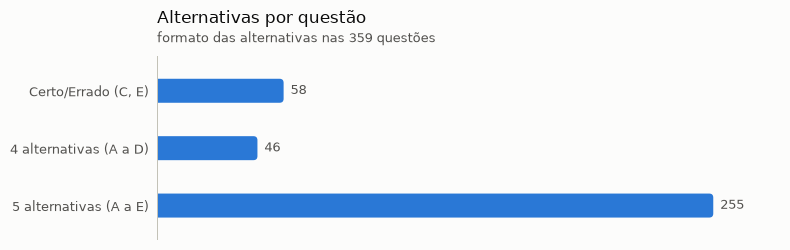

In [24]:
formatos = (
    questoes.groupby("formato")
    .agg(alternativas=("n_alternativas", "first"), questoes=("id", "size"))
    .sort_values("alternativas")
)
fig, ax = nova_figura(8, 2.6, "Alternativas por questão", "formato das alternativas nas 359 questões")
posicoes, espessura = preparar_barras_h(fig, ax, formatos.index, formatos["questoes"].max() * 1.12)
for y, valor in zip(posicoes, formatos["questoes"]):
    barra(ax, 0, valor, y, espessura, SERIE_1)
    rotulo_na_ponta(ax, valor, y, str(valor))
plt.show()

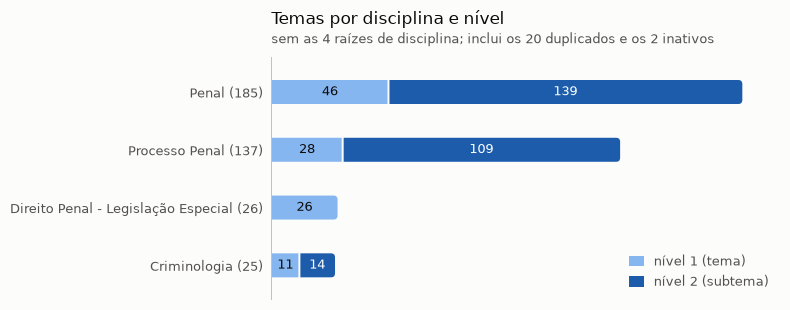

In [25]:
niveis = pd.crosstab(temas["disciplina"], temas["nivel"])[[1, 2]]
niveis["total"] = niveis.sum(axis=1)
niveis = niveis.sort_values("total", ascending=False)
rotulos = [f"{disciplina} ({total})" for disciplina, total in niveis["total"].items()]
fig, ax = nova_figura(8, 3.2, "Temas por disciplina e nível",
                      "sem as 4 raízes de disciplina; inclui os 20 duplicados e os 2 inativos")
posicoes, espessura = preparar_barras_h(fig, ax, rotulos, niveis["total"].max() * 1.08)
for y, (n1, n2) in zip(posicoes, zip(niveis[1], niveis[2])):
    barra(ax, 0, n1, y, espessura, NIVEL_1, arredondar=n2 == 0, recuo_fim=FOLGA / 2 if n2 else 0)
    rotulo_no_segmento(ax, 0, n1, y, str(n1), TINTA)
    if n2:
        barra(ax, n1, n1 + n2, y, espessura, NIVEL_2, recuo_inicio=FOLGA / 2)
        rotulo_no_segmento(ax, n1, n1 + n2, y, str(n2), "#ffffff")
legenda(ax, [("barra", NIVEL_1, "nível 1 (tema)"), ("barra", NIVEL_2, "nível 2 (subtema)")], loc="lower right")
plt.show()

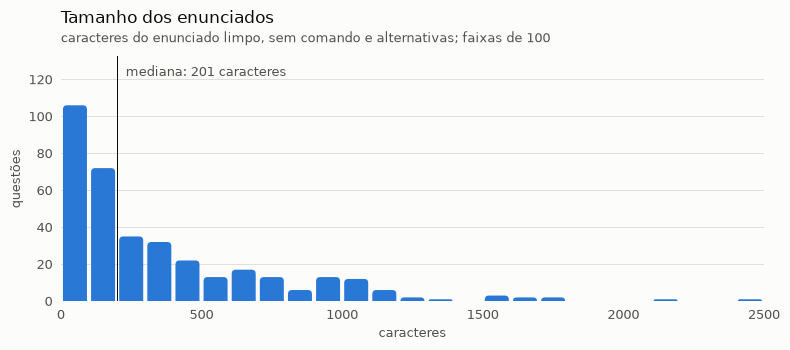

In [26]:
bordas = np.arange(0, 2600, 100)
contagens, _ = np.histogram(tamanho, bins=bordas)
fig, ax = nova_figura(8, 3.6, "Tamanho dos enunciados",
                      "caracteres do enunciado limpo, sem comando e alternativas; faixas de 100")
ax.set_xlim(0, bordas[-1])
ax.set_ylim(0, contagens.max() * 1.25)
ax.set_xticks(range(0, 2501, 500))
ax.grid(axis="y", color=GRADE, linewidth=PX)
ax.axhline(0, color=EIXO, linewidth=PX, zorder=3)
ax.set_ylabel("questões", color=TINTA_SECUNDARIA, fontsize=9)
ax.set_xlabel("caracteres", color=TINTA_SECUNDARIA, fontsize=9)
fig.tight_layout()
largura_px = abs(ax.transData.transform((100, 0))[0] - ax.transData.transform((0, 0))[0]) - FOLGA
for esquerda, n in zip(bordas[:-1], contagens):
    barra(ax, 0, n, esquerda + 50, min(largura_px, ESPESSURA_MAXIMA), SERIE_1, horizontal=False)
mediana = tamanho.median()
ax.axvline(mediana, color=TINTA, linewidth=PX, zorder=4)
ax.annotate(f"mediana: {mediana:.0f} caracteres", xy=(mediana, contagens.max() * 1.17), xytext=(6, 0),
            textcoords="offset points", fontsize=9, color=TINTA_SECUNDARIA, va="center")
plt.show()

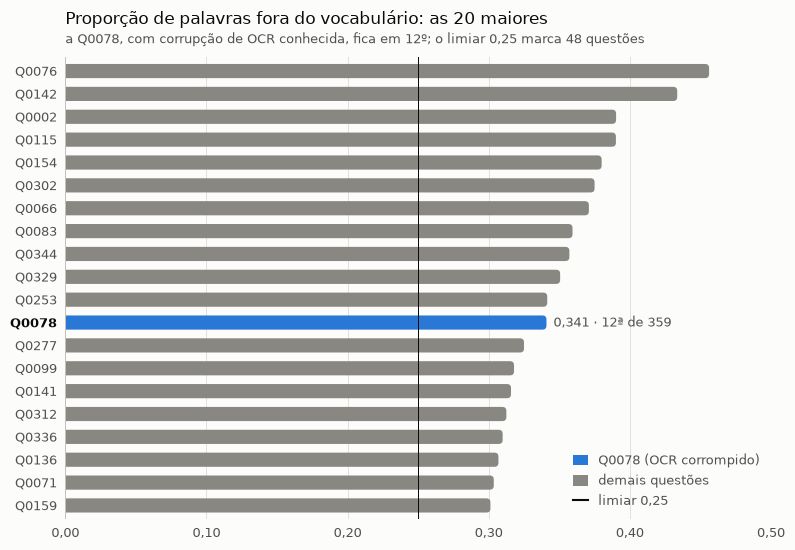

In [27]:
topo20 = ocr.head(20)
fig, ax = nova_figura(8, 5.6, "Proporção de palavras fora do vocabulário: as 20 maiores",
                      f"a Q0078, com corrupção de OCR conhecida, fica em {q0078['posicao']}º; "
                      f"o limiar 0,25 marca {ocr['suspeita'].sum()} questões")
posicoes, espessura = preparar_barras_h(fig, ax, topo20["id"], 0.5, eixo_de_valor=True, formato=virgula(2))
for y, id_questao, valor in zip(posicoes, topo20["id"], topo20["proporcao"]):
    barra(ax, 0, valor, y, espessura, SERIE_1 if id_questao == "Q0078" else CONTEXTO)
    if id_questao == "Q0078":
        rotulo_na_ponta(ax, valor, y, f"{valor:.3f}".replace(".", ",") + f" · {q0078['posicao']}ª de {len(ocr)}")
for rotulo in ax.get_yticklabels():
    if rotulo.get_text() == "Q0078":
        rotulo.set_color(TINTA)
        rotulo.set_fontweight("bold")
ax.axvline(0.25, color=TINTA, linewidth=PX, zorder=4)
legenda(ax, [("barra", SERIE_1, "Q0078 (OCR corrompido)"), ("barra", CONTEXTO, "demais questões"),
             ("linha", TINTA, "limiar 0,25")], loc="lower right")
plt.show()

## 7. Implicações para o pipeline

- **Alternativas no texto.** 20 enunciados são genéricos ("Assinale a alternativa CORRETA.") e três grupos repetem o mesmo enunciado, seis questões no maior. Sem as alternativas, Q0090 e Q0205 seriam o mesmo texto. Por isso o texto de classificação junta enunciado, comando e alternativas (`montar_texto`), e nada no pipeline deduplica por enunciado.
- **Canonicalização dos duplicados.** Os 20 temas de 6716 a 6738 não têm descrição e repetem temas existentes. `ArvoreTemas` converte cada um no canônico, 17 por título normalizado e 3 pela tabela de exceções, e nenhum aparece em `publicacao.csv`. O canônico 4696 tem o título errado "Estaturo de Idoso - Crimes": o id é o certo, e o título vai para o relatório.
- **`fora` vem do conteúdo, não do rótulo.** Das 8 questões com disciplina de origem fora do escopo, só a Q0142 (ITCD) é de outra matéria; as outras sete são penais. A decisão `fora` sai dos votos dos modelos sobre o texto, e o prompt não mostra `disciplina_origem` nem `assunto_origem`.
- **Lixeiras.** Dos 6 assuntos de origem mais frequentes, só "Teoria da Pena (Parte 02)" descreve bem as questões amostradas (seção 3), então `assunto_origem` não entra no prompt nem na busca de candidatos. A comparação com a decisão do pipeline fica para depois da execução.
- **Temas introdutórios.** A árvore tem temas largos, como "Conceito e Fontes do Direito Penal" (5171), "Princípios do Direito Penal" (5172) e "Princípios do Processo Penal" (5582), que atraem questões genéricas do mesmo jeito que as lixeiras. O prompt só deixa escolhê-los quando a questão é sobre o conceito ou o princípio em si, nunca por serem o tema mais genérico.
- **OCR como triagem.** A heurística ordena para leitura humana, não detecta: a Q0078 fica em 12º, atrás de 11 questões limpas. O texto não é corrigido e a marca não muda a decisão; ela vai para o relatório, e a Q0078 continua legível o bastante para ser classificada.
- **Temas inativos e sem questões.** Os 2 inativos (5078, 5234) ficam fora dos candidatos. Os 7 com zero questões na fonte continuam candidatos, porque o tema existe e só não tinha questões; a contagem sai do documento do tema que vira embedding (`ArvoreTemas.documento`).
- **Limpeza do texto.** `limpar_html` tira as tags, o HTML do Word da Q0099 e os `\t` literais da Q0240. Nenhuma questão tem imagem, então a limpeza não perde conteúdo.